# NPZ Label Sanity Check

End-to-end validation of the PSI-labeled NPZ shards produced by the Imm_cell_rMATS pipeline.
Covers schema integrity, label distributions, coverage statistics, cross-cell-type relationships,
cross-split consistency, sequence composition, and a visual example browser.

**Expected data layout:**
```
{DATA_DIR}/
  train/shard_*.npz
  val/shard_*.npz
  test/shard_*.npz
```

**NPZ schema per shard:**
| Key | Shape | Meaning |
|---|---|---|
| `sequence` | (N, 524288, 4) | One-hot ACGT |
| `targets` | (N, 16384, 3) | Soft PSI per bin per cell type |
| `confidence` | (N, 16384, 3) | log1p(IJC+SJC) rasterized |
| `mask` | (N, 16384, 3) | 1.0 = valid label |
| `chrom` | (N,) | Chromosome string |
| `window_start` | (N,) | Window start (bp, 0-based) |
| `window_end` | (N,) | Window end (bp) |
| `has_signal` | (N,) | 1.0 if window contains any labeled bin |
| `celltype_idx_k` | scalar | Cell type name at task index k |

In [1]:
# ============================================================
# CELL 1 — Config  (edit paths here)
# ============================================================
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
matplotlib.rcParams.update({'figure.dpi': 100, 'font.size': 11})

# ---- paths ----
DATA_DIR = (
    "/mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS"
    "/data_labeling/results/labelled_data/multitask_balanced"
)

# ---- sampling ----
# Number of shards to load per split for label-distribution / coverage sections.
# Raise for more thorough statistics; lower for faster iteration.
N_SHARDS_SAMPLE = 5
# Shards to use for sequence-composition (sequence array is large; keep <=2).
N_SHARDS_SEQ = 1

# ---- expected schema ----
WINDOW_BP = 524_288
BIN_BP    = 32
N_BINS    = WINDOW_BP // BIN_BP   # 16 384
N_TASKS   = 3
SPLITS    = ["train", "val", "test"]

EXPECTED_CHROMS = {f"chr{i}" for i in range(1, 23)} | {"chrX", "chrY"}
EXPECTED_SPLIT_CHROMS = {
    "val":  {"chr10"},
    "test": {"chr11"},
    "train": EXPECTED_CHROMS - {"chr10", "chr11"},
}

CELL_COLORS = {"B_Cell": "#2196F3", "T_Cell": "#4CAF50", "Macrophage": "#FF9800"}
SPLIT_COLORS = {"train": "#1f77b4", "val": "#ff7f0e", "test": "#2ca02c"}

print(f"DATA_DIR : {DATA_DIR}")
print(f"N_BINS   : {N_BINS}")

DATA_DIR : /mnt/data_sda/jdearborn/scratch/Imm_cell_rMATS/data_labeling/results/labelled_data/multitask_balanced
N_BINS   : 16384


In [2]:
# ============================================================
# CELL 2 — Helper functions
# ============================================================

def get_shard_files(split):
    path = os.path.join(DATA_DIR, split, "*.npz")
    return sorted(glob.glob(path))


def load_metadata_only(shard_files):
    """Lightweight load: chrom, window coords, has_signal only.
    Used for inventory over ALL shards without loading targets/sequence."""
    rows = []
    celltype_map = {}
    for f in shard_files:
        d = np.load(f, allow_pickle=True)
        n = len(d["has_signal"])
        fname = os.path.basename(f)
        for i in range(n):
            rows.append({
                "file": fname,
                "chrom": str(d["chrom"][i]),
                "window_start": int(d["window_start"][i]),
                "window_end":   int(d["window_end"][i]),
                "has_signal":   float(d["has_signal"][i]),
            })
        if not celltype_map:
            for key in d.files:
                if key.startswith("celltype_idx_"):
                    idx = int(key.rsplit("_", 1)[-1])
                    celltype_map[idx] = str(d[key])
    return pd.DataFrame(rows), celltype_map


def load_labels(shard_files, max_shards=None):
    """Load targets, confidence, mask + coord arrays from up to max_shards shards."""
    files = shard_files[:max_shards] if max_shards else shard_files
    keys = ["targets", "confidence", "mask", "has_signal",
            "chrom", "window_start", "window_end"]
    acc = {k: [] for k in keys}
    celltype_map = {}
    for f in files:
        d = np.load(f, allow_pickle=True)
        for k in keys:
            acc[k].append(d[k])
        if not celltype_map:
            for key in d.files:
                if key.startswith("celltype_idx_"):
                    idx = int(key.rsplit("_", 1)[-1])
                    celltype_map[idx] = str(d[key])
    return {k: np.concatenate(v) for k, v in acc.items()}, celltype_map


def cell_color(ct):
    return CELL_COLORS.get(ct, "#888")


print("Helper functions defined.")

Helper functions defined.


In [3]:
# ============================================================
# CELL 3 — Load data
# ============================================================

all_shards = {s: get_shard_files(s) for s in SPLITS}
for s, files in all_shards.items():
    if not files:
        print(f"  WARNING: no shards found for split '{s}' in {DATA_DIR}")
    else:
        print(f"  {s}: {len(files)} shards")

# --- full metadata (lightweight, all shards) ---
print("\nLoading metadata (all shards)...")
meta = {}
celltype_map = {}
for s in SPLITS:
    meta[s], cm = load_metadata_only(all_shards[s])
    meta[s]["split"] = s
    if cm:
        celltype_map = cm
    print(f"  {s}: {len(meta[s])} examples")

CELL_TYPES = [celltype_map.get(i, f"task_{i}") for i in range(N_TASKS)]
print(f"\nCell types (task order): {CELL_TYPES}")

# --- label arrays (sampled shards) ---
print(f"\nLoading labels ({N_SHARDS_SAMPLE} shards/split)...")
labels = {}
for s in SPLITS:
    labels[s], _ = load_labels(all_shards[s], max_shards=N_SHARDS_SAMPLE)
    print(f"  {s}: {labels[s]['targets'].shape[0]} examples")

  train: 44 shards
  val: 2 shards
  test: 2 shards

Loading metadata (all shards)...
  train: 8725 examples
  val: 483 examples
  test: 453 examples

Cell types (task order): ['B_Cell', 'Macrophage', 'T_Cell']

Loading labels (5 shards/split)...
  train: 1236 examples
  val: 483 examples
  test: 453 examples


---
## Section 1 — Dataset Inventory
Total counts, signal balance, shard size uniformity, per-cell-type signal rates.

=== Example counts ===
  train :  8725 examples  |  signal=5952 (68.2%)
  val   :   483 examples  |  signal=338 (70.0%)
  test  :   453 examples  |  signal=349 (77.0%)


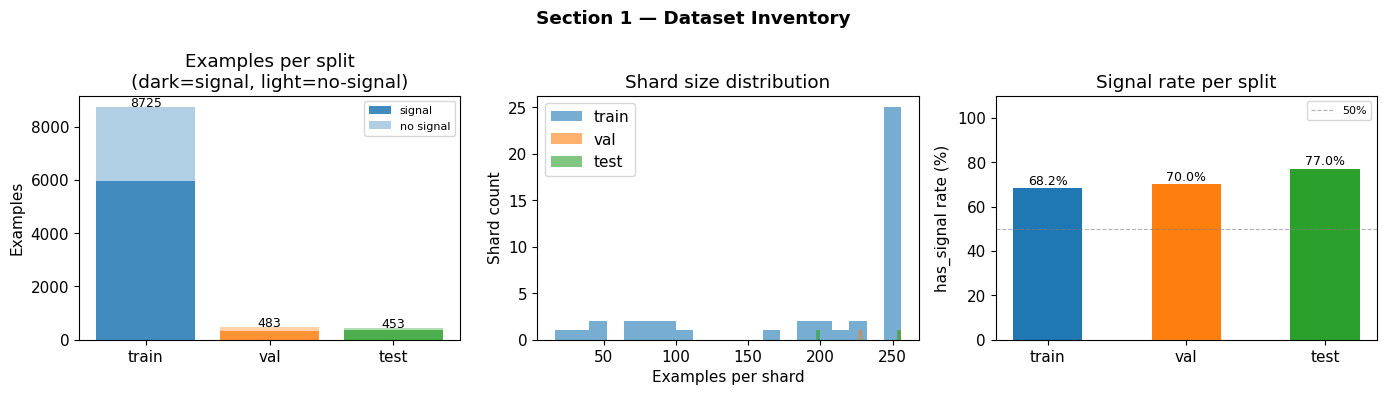

In [4]:
# ---- 1a. Example counts & signal balance ---
meta_all = pd.concat(meta.values(), ignore_index=True)

print("=== Example counts ===")
for s in SPLITS:
    m = meta[s]
    n_sig = (m["has_signal"] == 1).sum()
    print(f"  {s:6s}: {len(m):5d} examples  |  signal={n_sig} ({100*n_sig/len(m):.1f}%)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("Section 1 — Dataset Inventory", fontweight="bold")

# Plot 1: stacked bar — signal vs no-signal per split
ax = axes[0]
for i, s in enumerate(SPLITS):
    m = meta[s]
    n_sig   = (m["has_signal"] == 1).sum()
    n_nosig = (m["has_signal"] == 0).sum()
    ax.bar(s, n_sig,   color=SPLIT_COLORS[s], alpha=0.85, label="signal"   if i==0 else "")
    ax.bar(s, n_nosig, color=SPLIT_COLORS[s], alpha=0.35,
           bottom=n_sig, label="no signal" if i==0 else "")
    ax.text(i, n_sig + n_nosig + 10, str(n_sig + n_nosig), ha="center", fontsize=9)
ax.set_ylabel("Examples")
ax.set_title("Examples per split\n(dark=signal, light=no-signal)")
ax.legend(fontsize=8)

# Plot 2: examples per shard distribution
ax = axes[1]
for s in SPLITS:
    counts = meta[s].groupby("file").size().values
    ax.hist(counts, bins=20, alpha=0.6, color=SPLIT_COLORS[s], label=s)
ax.set_xlabel("Examples per shard")
ax.set_ylabel("Shard count")
ax.set_title("Shard size distribution")
ax.legend()

# Plot 3: has_signal rate per split (bar, one bar per split)
ax = axes[2]
rates = [meta[s]["has_signal"].mean() * 100 for s in SPLITS]
bars = ax.bar(SPLITS, rates, color=[SPLIT_COLORS[s] for s in SPLITS], width=0.5)
for bar, r in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2, r + 0.5,
            f"{r:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, 110)
ax.axhline(50, color="gray", linestyle="--", linewidth=0.8, alpha=0.6, label="50%")
ax.set_ylabel("has_signal rate (%)")
ax.set_title("Signal rate per split")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## Section 2 — Schema & Integrity Validation
Systematic checks across sampled shards. Renders a pass/fail table.

In [5]:
def run_shard_checks(shard_file):
    """Run all integrity checks on a single shard. Returns dict of (passed, detail)."""
    d = np.load(shard_file, allow_pickle=True)
    r = {}
    N = d["targets"].shape[0]

    # 1. Required keys present
    req = {"sequence", "targets", "confidence", "mask",
           "chrom", "window_start", "window_end", "has_signal"}
    missing = req - set(d.files)
    r["required_keys"] = (not missing, f"missing: {missing}" if missing else "all present")

    # 2. Shapes
    expected = {
        "targets":    (N, N_BINS, N_TASKS),
        "confidence": (N, N_BINS, N_TASKS),
        "mask":       (N, N_BINS, N_TASKS),
        "sequence":   (N, WINDOW_BP, 4),
    }
    bad = {k: f"{d[k].shape} ≠ {v}" for k, v in expected.items() if d[k].shape != v}
    r["array_shapes"] = (not bad, "; ".join(bad.values()) if bad else "OK")

    # 3. dtypes
    exp_dt = {
        "targets": np.float32, "confidence": np.float32,
        "mask": np.float32, "sequence": np.float32,
        "window_start": np.int64, "window_end": np.int64,
    }
    bad_dt = {k: str(d[k].dtype) for k, v in exp_dt.items() if d[k].dtype != v}
    r["dtypes"] = (not bad_dt, str(bad_dt) if bad_dt else "OK")

    # 4. Sequence values in {0, 1}
    seq = d["sequence"]
    nbad = int(((seq != 0) & (seq != 1)).sum())
    r["sequence_binary"] = (nbad == 0, f"{nbad} values ∉ {{0,1}}")

    # 5. Sequence position sums in {0, 1}  (N counts as 0)
    row_sums = seq.sum(axis=-1)  # (N, WINDOW_BP)
    bad_sums = int(((row_sums != 0) & (row_sums != 1)).sum())
    r["sequence_row_sums"] = (bad_sums == 0, f"{bad_sums} positions with sum ∉ {{0,1}}")

    tgt = d["targets"]
    msk = d["mask"]
    conf = d["confidence"]

    # 6. PSI in [0,1] for masked bins
    masked_psi = tgt[msk == 1]
    bad_psi = int(((masked_psi < -1e-6) | (masked_psi > 1 + 1e-6)).sum())
    r["psi_range"] = (bad_psi == 0, f"{bad_psi} values outside [0,1]")

    # 7. Confidence >= 0
    bad_conf = int((conf < -1e-6).sum())
    r["confidence_nonneg"] = (bad_conf == 0, f"{bad_conf} negative values")

    # 8. Mask in {0, 1}
    bad_mask = int(((msk != 0) & (msk != 1)).sum())
    r["mask_binary"] = (bad_mask == 0, f"{bad_mask} fractional values")

    # 9. mask–target consistency: target > 0 → mask == 1
    mt_viol = int(((tgt > 1e-6) & (msk == 0)).sum())
    r["mask_target_consistency"] = (mt_viol == 0, f"{mt_viol} violations")

    # 10. mask–confidence consistency: confidence > 0 → mask == 1
    mc_viol = int(((conf > 1e-6) & (msk == 0)).sum())
    r["mask_confidence_consistency"] = (mc_viol == 0, f"{mc_viol} violations")

    # 11. Window size exactly WINDOW_BP
    ws, we = d["window_start"], d["window_end"]
    bad_win = int(((we - ws) != WINDOW_BP).sum())
    r["window_size"] = (bad_win == 0, f"{bad_win} windows ≠ {WINDOW_BP} bp")

    # 12. window_start >= 0
    bad_start = int((ws < 0).sum())
    r["window_start_nonneg"] = (bad_start == 0, f"{bad_start} negative starts")

    # 13. has_signal in {0, 1}
    hs = d["has_signal"]
    bad_hs = int(((hs != 0) & (hs != 1)).sum())
    r["has_signal_binary"] = (bad_hs == 0, f"{bad_hs} non-0/1 values")

    # 14. NaN / Inf in targets, confidence, mask
    for arr_name in ["targets", "confidence", "mask"]:
        arr = d[arr_name]
        nans = int(np.isnan(arr).sum())
        infs = int(np.isinf(arr).sum())
        r[f"no_nan_inf_{arr_name}"] = (
            nans + infs == 0,
            f"{nans} NaN, {infs} Inf" if nans + infs else "OK"
        )

    # 15. celltype_idx metadata present
    ct_keys = [k for k in d.files if k.startswith("celltype_idx_")]
    r["celltype_metadata"] = (
        len(ct_keys) == N_TASKS,
        f"{len(ct_keys)} keys (expected {N_TASKS})"
    )
    return r


print("Running schema checks...")
all_results = {}
for s in SPLITS:
    all_results[s] = [run_shard_checks(f) for f in all_shards[s][:N_SHARDS_SAMPLE]]
    print(f"  {s}: {len(all_results[s])} shards checked")

# Aggregate across splits and shards
check_names = [k for k in next(iter(all_results[SPLITS[0]])).keys()]
summary = {}
for name in check_names:
    failures = []
    for s, results in all_results.items():
        for i, r in enumerate(results):
            passed, detail = r[name]
            if not passed:
                fname = os.path.basename(all_shards[s][i])
                failures.append(f"{s}/{fname}: {detail}")
    summary[name] = (not failures, failures[:3])

# Render HTML table
rows_html = []
for name, (passed, failures) in summary.items():
    bg  = "#c8e6c9" if passed else "#ffcdd2"
    ico = "✅" if passed else "❌"
    detail = "PASS" if passed else "<br>".join(failures[:3])
    label = name.replace("_", " ").title()
    rows_html.append(
        f'<tr style="background:{bg}">'
        f'<td style="padding:3px 10px">{ico} {label}</td>'
        f'<td style="padding:3px 10px; font-family:monospace">{detail}</td></tr>'
    )

table_html = (
    '<table style="border-collapse:collapse; font-size:13px">'
    '<thead><tr>'
    '<th style="text-align:left;padding:4px 10px">Check</th>'
    '<th style="text-align:left;padding:4px 10px">Result</th>'
    '</tr></thead><tbody>' + "".join(rows_html) + "</tbody></table>"
)
display(HTML(table_html))

Running schema checks...
  train: 5 shards checked
  val: 2 shards checked
  test: 2 shards checked


Check,Result
✅ Required Keys,PASS
✅ Array Shapes,PASS
✅ Dtypes,PASS
✅ Sequence Binary,PASS
✅ Sequence Row Sums,PASS
✅ Psi Range,PASS
✅ Confidence Nonneg,PASS
✅ Mask Binary,PASS
✅ Mask Target Consistency,PASS
✅ Mask Confidence Consistency,PASS


---
## Section 3 — PSI Label Distributions
Masked bins only. Expect a roughly bimodal distribution (skipped ≈ 0, included ≈ 1) with
a regulated minority in the middle.

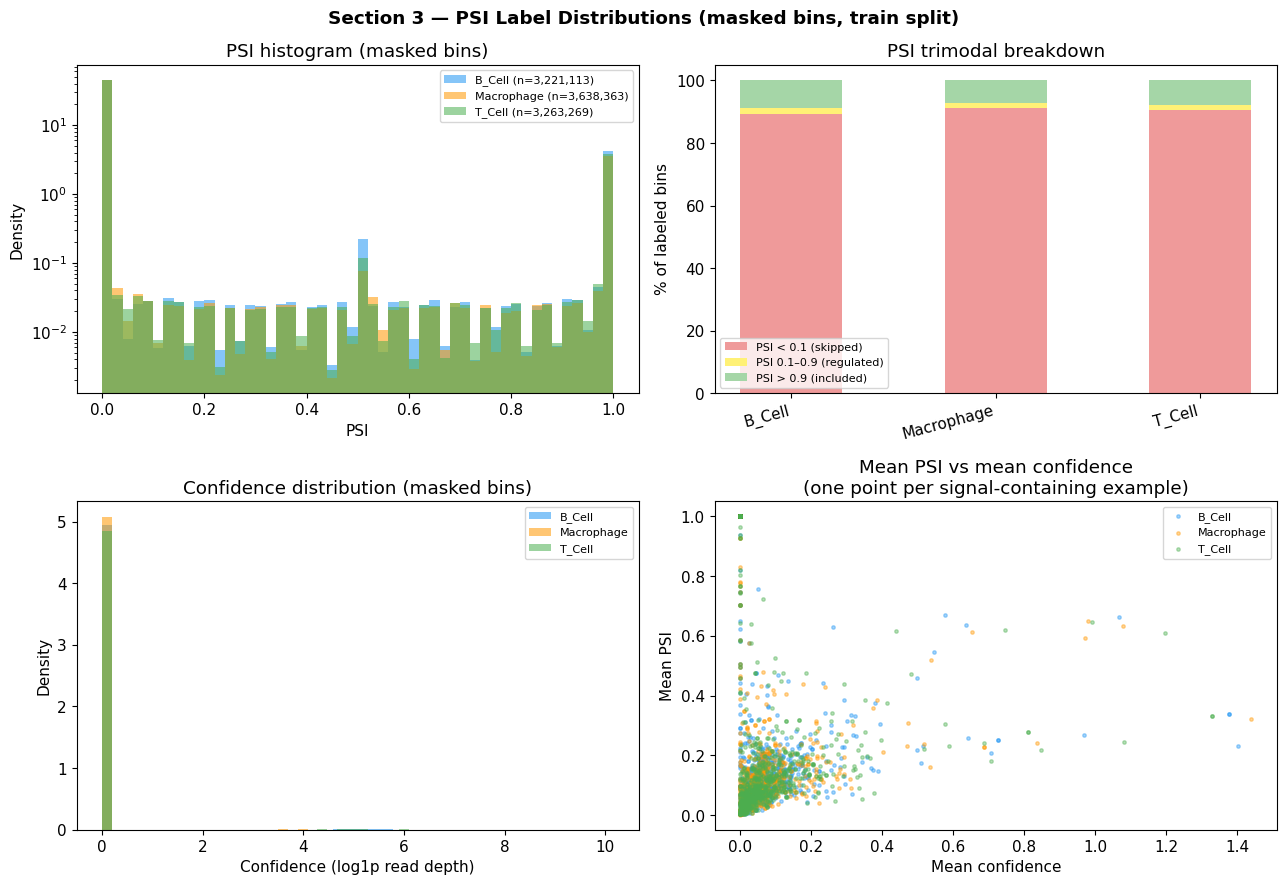

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Section 3 — PSI Label Distributions (masked bins, train split)",
             fontweight="bold")

lbl = labels["train"]
tgt, conf, msk = lbl["targets"], lbl["confidence"], lbl["mask"]

# ---- Plot 1: PSI histogram per cell type ----
ax = axes[0, 0]
for i, ct in enumerate(CELL_TYPES):
    m = msk[:, :, i] == 1
    vals = tgt[:, :, i][m]
    ax.hist(vals, bins=50, density=True, alpha=0.55,
            color=cell_color(ct), label=f"{ct} (n={len(vals):,})")
ax.set_xlabel("PSI")
ax.set_ylabel("Density")
ax.set_title("PSI histogram (masked bins)")
ax.set_yscale("log")
ax.legend(fontsize=8)

# ---- Plot 2: PSI trimodal summary ----
ax = axes[0, 1]
x = np.arange(N_TASKS)
skipped, regulated, included = [], [], []
for i in range(N_TASKS):
    m = msk[:, :, i] == 1
    vals = tgt[:, :, i][m]
    total = len(vals) if len(vals) > 0 else 1
    skipped.append(  (vals <  0.1).sum() / total * 100)
    regulated.append(((vals >= 0.1) & (vals <= 0.9)).sum() / total * 100)
    included.append( (vals >  0.9).sum() / total * 100)

ax.bar(x, skipped,   label="PSI < 0.1 (skipped)",    color="#ef9a9a", width=0.5)
ax.bar(x, regulated, label="PSI 0.1–0.9 (regulated)", color="#fff176", width=0.5,
       bottom=skipped)
ax.bar(x, included,  label="PSI > 0.9 (included)",    color="#a5d6a7", width=0.5,
       bottom=[s+r for s, r in zip(skipped, regulated)])
ax.set_xticks(x)
ax.set_xticklabels(CELL_TYPES, rotation=15, ha="right")
ax.set_ylabel("% of labeled bins")
ax.set_title("PSI trimodal breakdown")
ax.legend(fontsize=8)

# ---- Plot 3: Confidence histogram ----
ax = axes[1, 0]
for i, ct in enumerate(CELL_TYPES):
    m = msk[:, :, i] == 1
    vals = conf[:, :, i][m]
    ax.hist(vals, bins=50, density=True, alpha=0.55,
            color=cell_color(ct), label=ct)
ax.set_xlabel("Confidence (log1p read depth)")
ax.set_ylabel("Density")
ax.set_title("Confidence distribution (masked bins)")
ax.legend(fontsize=8)

# ---- Plot 4: mean PSI vs mean confidence per example ----
ax = axes[1, 1]
for i, ct in enumerate(CELL_TYPES):
    m_per_ex = msk[:, :, i].sum(axis=1) > 0   # examples with signal in this task
    ex_idx = np.where(m_per_ex)[0]
    if len(ex_idx) == 0:
        continue
    mean_psi  = np.array([tgt[j, msk[j, :, i] == 1, i].mean() for j in ex_idx])
    mean_conf = np.array([conf[j, msk[j, :, i] == 1, i].mean() for j in ex_idx])
    ax.scatter(mean_conf, mean_psi, s=6, alpha=0.4,
               color=cell_color(ct), label=ct)

ax.set_xlabel("Mean confidence")
ax.set_ylabel("Mean PSI")
ax.set_title("Mean PSI vs mean confidence\n(one point per signal-containing example)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## Section 4 — Mask / Coverage Statistics
How densely are windows labeled? Where in the window does signal tend to fall?

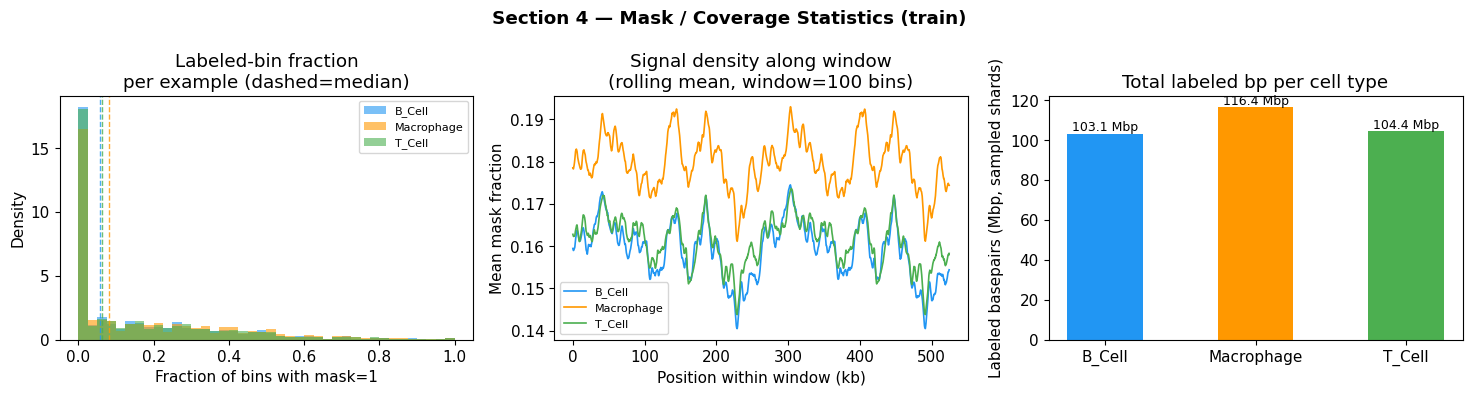


=== Mask statistics (train, sampled shards) ===
Cell type       Mean frac  Median frac   % examples w/ signal
B_Cell             0.1591       0.0584                  64.4%
Macrophage         0.1797       0.0824                  66.7%
T_Cell             0.1611       0.0620                  65.0%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Section 4 — Mask / Coverage Statistics (train)", fontweight="bold")

lbl = labels["train"]
msk = lbl["mask"]

# ---- Plot 1: labeled-bin fraction per example ----
ax = axes[0]
for i, ct in enumerate(CELL_TYPES):
    frac = msk[:, :, i].sum(axis=1) / N_BINS
    ax.hist(frac, bins=40, alpha=0.6, density=True,
            color=cell_color(ct), label=ct)
    ax.axvline(np.median(frac), color=cell_color(ct), linestyle="--",
               linewidth=1, alpha=0.8)
ax.set_xlabel("Fraction of bins with mask=1")
ax.set_ylabel("Density")
ax.set_title("Labeled-bin fraction\nper example (dashed=median)")
ax.legend(fontsize=8)

# ---- Plot 2: mean mask fraction by bin position ----
ax = axes[1]
# Smooth with rolling window for readability
roll = 100
bin_positions = np.arange(N_BINS) * BIN_BP
for i, ct in enumerate(CELL_TYPES):
    mean_per_bin = msk[:, :, i].mean(axis=0)   # (N_BINS,)
    smoothed = pd.Series(mean_per_bin).rolling(roll, center=True, min_periods=1).mean().values
    ax.plot(bin_positions / 1e3, smoothed, color=cell_color(ct), label=ct, linewidth=1.2)
ax.set_xlabel("Position within window (kb)")
ax.set_ylabel("Mean mask fraction")
ax.set_title(f"Signal density along window\n(rolling mean, window={roll} bins)")
ax.legend(fontsize=8)

# ---- Plot 3: labeled basepairs per cell type ----
ax = axes[2]
total_labeled_bp = [msk[:, :, i].sum() * BIN_BP for i in range(N_TASKS)]
bars = ax.bar(CELL_TYPES, [v / 1e6 for v in total_labeled_bp],
              color=[cell_color(ct) for ct in CELL_TYPES], width=0.5)
for bar, bp in zip(bars, total_labeled_bp):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f"{bp/1e6:.1f} Mbp",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Labeled basepairs (Mbp, sampled shards)")
ax.set_title("Total labeled bp per cell type")

plt.tight_layout()
plt.show()

# Summary stats
print("\n=== Mask statistics (train, sampled shards) ===")
print(f"{'Cell type':<14} {'Mean frac':>10} {'Median frac':>12} {'% examples w/ signal':>22}")
for i, ct in enumerate(CELL_TYPES):
    frac = msk[:, :, i].sum(axis=1) / N_BINS
    pct_sig = (frac > 0).mean() * 100
    print(f"{ct:<14} {frac.mean():>10.4f} {np.median(frac):>12.4f} {pct_sig:>21.1f}%")

---
## Section 5 — Cross-Cell-Type Comparison
How often do events co-occur across cell types? Are PSI values correlated?

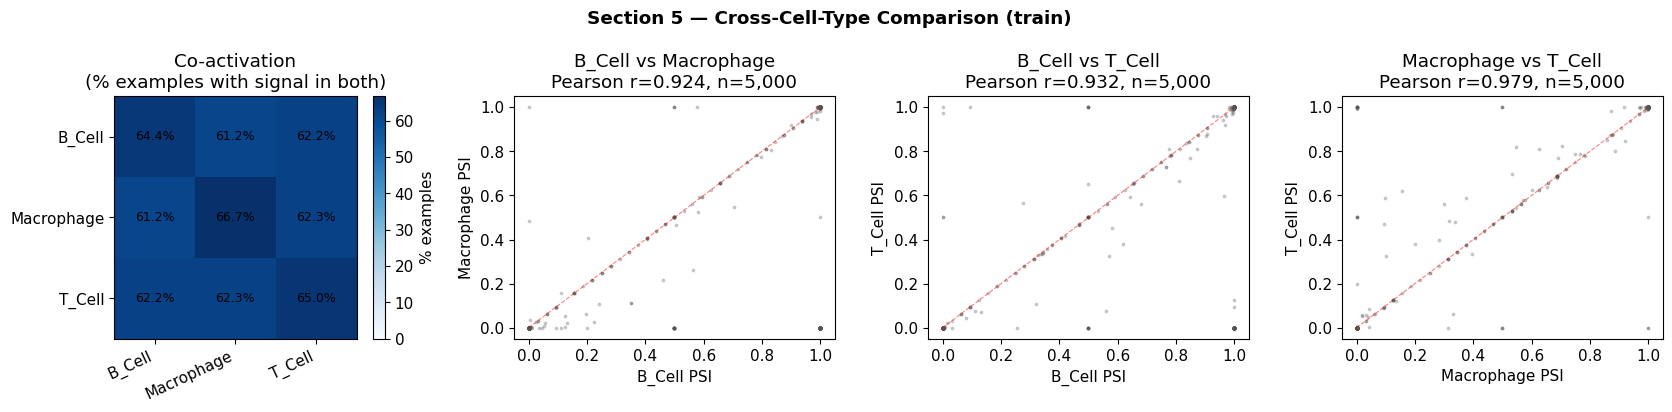

In [8]:
lbl = labels["train"]
tgt, msk = lbl["targets"], lbl["mask"]

# Per-example signal presence: (N, N_TASKS) boolean
ex_has_signal = msk.sum(axis=1) > 0   # (N, N_TASKS)
N = tgt.shape[0]

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
fig.suptitle("Section 5 — Cross-Cell-Type Comparison (train)", fontweight="bold")

# ---- Plot 1: Co-activation heatmap ----
ax = axes[0]
coact = np.zeros((N_TASKS, N_TASKS))
for i in range(N_TASKS):
    for j in range(N_TASKS):
        coact[i, j] = (ex_has_signal[:, i] & ex_has_signal[:, j]).sum() / N * 100

im = ax.imshow(coact, cmap="Blues", vmin=0)
plt.colorbar(im, ax=ax, label="% examples")
ax.set_xticks(range(N_TASKS)); ax.set_xticklabels(CELL_TYPES, rotation=25, ha="right")
ax.set_yticks(range(N_TASKS)); ax.set_yticklabels(CELL_TYPES)
for i in range(N_TASKS):
    for j in range(N_TASKS):
        ax.text(j, i, f"{coact[i, j]:.1f}%", ha="center", va="center", fontsize=9)
ax.set_title("Co-activation\n(% examples with signal in both)")

# ---- Plots 2-4: PSI scatter for each cell-type pair ----
pairs = [(0, 1), (0, 2), (1, 2)]
for ax_idx, (i, j) in enumerate(pairs):
    ax = axes[ax_idx + 1]
    ct_i, ct_j = CELL_TYPES[i], CELL_TYPES[j]

    # Bins labeled in BOTH tasks simultaneously
    both_mask = (msk[:, :, i] == 1) & (msk[:, :, j] == 1)
    psi_i = tgt[:, :, i][both_mask]
    psi_j = tgt[:, :, j][both_mask]

    if len(psi_i) < 10:
        ax.text(0.5, 0.5, "insufficient co-labeled bins",
                ha="center", va="center", transform=ax.transAxes, fontsize=9)
        ax.set_title(f"{ct_i} vs {ct_j}")
        continue

    # Downsample for speed
    max_pts = 5_000
    if len(psi_i) > max_pts:
        idx = np.random.choice(len(psi_i), max_pts, replace=False)
        psi_i, psi_j = psi_i[idx], psi_j[idx]

    r, p = stats.pearsonr(psi_i, psi_j)
    ax.scatter(psi_i, psi_j, s=3, alpha=0.25, color="#555", rasterized=True)
    ax.plot([0, 1], [0, 1], "r--", linewidth=0.8, alpha=0.5)
    ax.set_xlabel(f"{ct_i} PSI")
    ax.set_ylabel(f"{ct_j} PSI")
    ax.set_title(
        f"{ct_i} vs {ct_j}\n"
        f"Pearson r={r:.3f}, n={len(psi_i):,}"
    )
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

---
## Section 6 — Cross-Split Consistency
Distributions and chromosome assignments should be consistent across train / val / test.

Cell type,train vs val,train vs test
B_Cell,D=0.011 (p=1.03e-94),D=0.015 (p=6.64e-235)
Macrophage,D=0.007 (p=2.49e-45),D=0.023 (p=0.00e+00)
T_Cell,D=0.011 (p=7.64e-102),D=0.021 (p=0.00e+00)


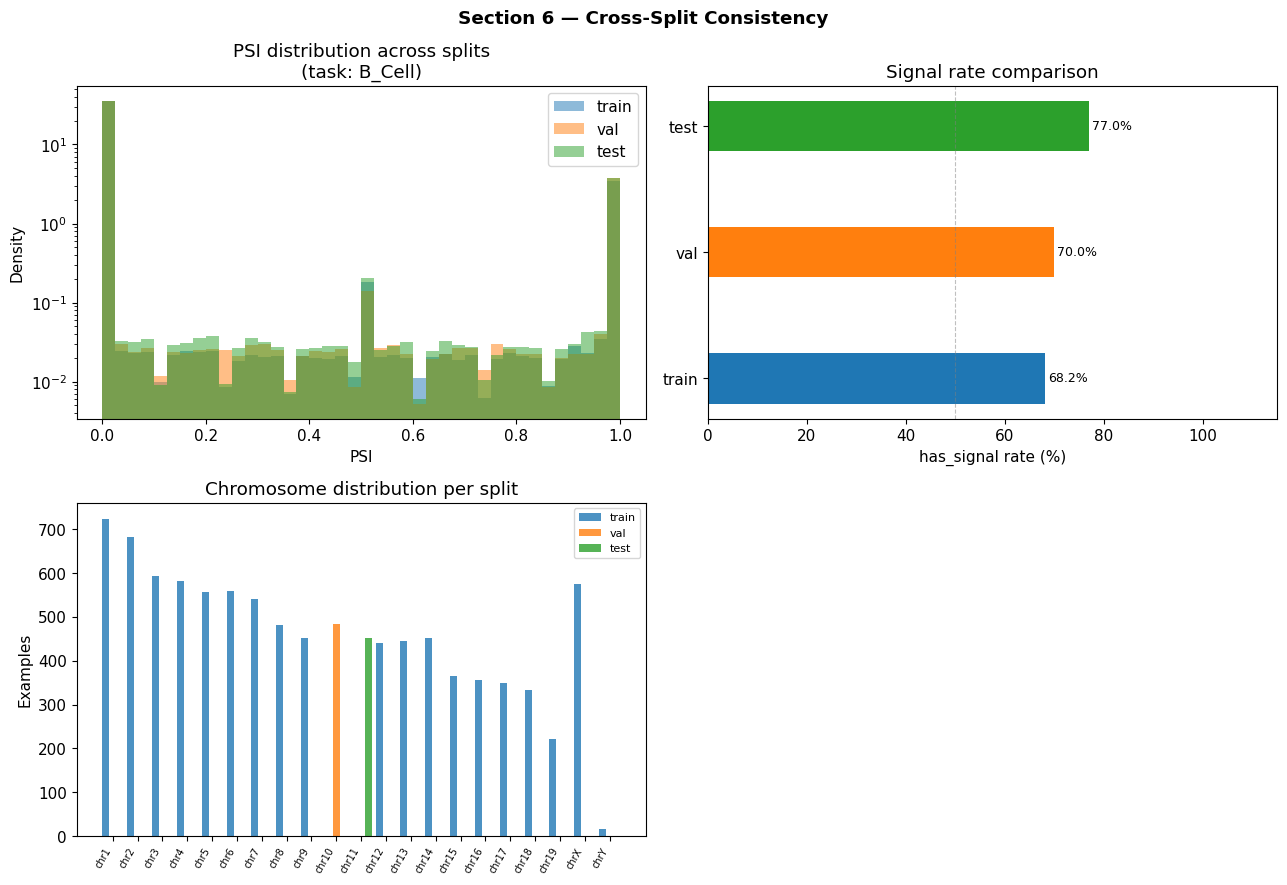

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Section 6 — Cross-Split Consistency", fontweight="bold")

# ---- Plot 1: Overlaid PSI histogram (one subplot per cell type, first task shown) ----
# Use task index 0 as representative
ax = axes[0, 0]
task_idx = 0
for s in SPLITS:
    lbl = labels[s]
    m = lbl["mask"][:, :, task_idx] == 1
    vals = lbl["targets"][:, :, task_idx][m]
    ax.hist(vals, bins=40, density=True, alpha=0.5,
            color=SPLIT_COLORS[s], label=s)
ax.set_xlabel("PSI")
ax.set_ylabel("Density")
ax.set_title(f"PSI distribution across splits\n(task: {CELL_TYPES[task_idx]})")
ax.set_yscale("log")
ax.legend()

# ---- Plot 2: has_signal rate across splits ----
ax = axes[0, 1]
rates = {s: meta[s]["has_signal"].mean() * 100 for s in SPLITS}
colors = [SPLIT_COLORS[s] for s in SPLITS]
bars = ax.barh(SPLITS, [rates[s] for s in SPLITS], color=colors, height=0.4)
for bar, s in zip(bars, SPLITS):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{rates[s]:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 115)
ax.axvline(50, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.set_xlabel("has_signal rate (%)")
ax.set_title("Signal rate comparison")

# ---- Plot 3: Chromosome distribution ----
ax = axes[1, 0]
all_chroms = sorted(meta_all["chrom"].unique(),
                    key=lambda c: int(c.replace("chr", "").replace("X", "23").replace("Y", "24")))
x = np.arange(len(all_chroms))
width = 0.28
for idx, s in enumerate(SPLITS):
    chrom_counts = meta[s]["chrom"].value_counts()
    vals = [chrom_counts.get(c, 0) for c in all_chroms]
    ax.bar(x + idx * width, vals, width, label=s, color=SPLIT_COLORS[s], alpha=0.8)
ax.set_xticks(x + width)
ax.set_xticklabels(all_chroms, rotation=60, ha="right", fontsize=7)
ax.set_ylabel("Examples")
ax.set_title("Chromosome distribution per split")
ax.legend(fontsize=8)

# ---- Plot 4 + KS tests ----
ax = axes[1, 1]
ax.axis("off")

ks_rows = []
ks_rows.append("<b>KS test: PSI distributions</b><br>")
ks_rows.append('<table style="font-size:12px; border-collapse:collapse">')
ks_rows.append("<tr><th>Cell type</th><th>train vs val</th><th>train vs test</th></tr>")
WARN_D = 0.05
for task_i, ct in enumerate(CELL_TYPES):
    psi = {}
    for s in SPLITS:
        lbl = labels[s]
        m = lbl["mask"][:, :, task_i] == 1
        psi[s] = lbl["targets"][:, :, task_i][m]

    def fmt_ks(a, b):
        if len(a) < 2 or len(b) < 2:
            return "n/a"
        d, p = stats.ks_2samp(a, b)
        color = "#ffcdd2" if d > WARN_D else "#c8e6c9"
        return f'<td style="background:{color};padding:2px 6px">D={d:.3f} (p={p:.2e})</td>'

    row = (f"<tr><td style='padding:2px 6px'>{ct}</td>"
           + fmt_ks(psi["train"], psi["val"])
           + fmt_ks(psi["train"], psi["test"]) + "</tr>")
    ks_rows.append(row)

ks_rows.append("</table>")
ks_rows.append(f"<br><i>Flag if D > {WARN_D}</i>")

# Chrom assignment check
ks_rows.append("<br><br><b>Chromosome assignment check</b><br>")
for s in SPLITS:
    actual = set(meta[s]["chrom"].unique())
    expected = EXPECTED_SPLIT_CHROMS.get(s, set())
    unexpected = actual - EXPECTED_CHROMS
    # For val/test check exact match; for train just check no val/test chroms present
    if s in ("val", "test"):
        wrong = actual - expected
        icon = "✅" if not wrong else "❌"
        ks_rows.append(f"{icon} {s}: chroms = {sorted(actual)} (expected {sorted(expected)})<br>")
    else:
        contamination = actual & {"chr10", "chr11"}
        icon = "✅" if not contamination else "❌"
        ks_rows.append(f"{icon} train: {'no val/test chrom contamination' if not contamination else f'contains {contamination}'}<br>")

display(HTML("".join(ks_rows)))

plt.tight_layout()
plt.show()

---
## Section 7 — Sequence Composition
GC content distribution and per-position base frequency. Uses a small number of shards
(`N_SHARDS_SEQ`) due to the large size of sequence arrays.

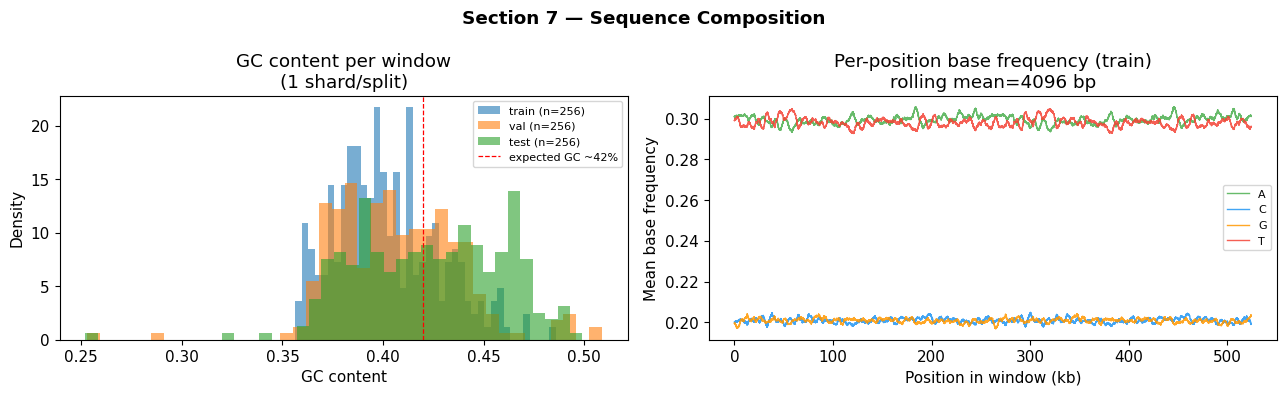


=== GC content statistics ===
  train : mean=0.4019  std=0.0255  min=0.3564  max=0.4860
  val   : mean=0.4071  std=0.0322  min=0.2528  max=0.5089
  test  : mean=0.4230  std=0.0365  min=0.2520  max=0.4991


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("Section 7 — Sequence Composition", fontweight="bold")

# ---- Plot 1: GC content histogram per split ----
ax = axes[0]
gc_all = {}
for s in SPLITS:
    files = all_shards[s][:N_SHARDS_SEQ]
    gc_vals = []
    for f in files:
        d = np.load(f, allow_pickle=True, mmap_mode="r")
        seq = d["sequence"]   # (N, WINDOW_BP, 4) — memory-mapped
        # G + C are channels 2 (G) and 1 (C) in standard one-hot ACGT
        gc = (seq[:, :, 1] + seq[:, :, 2]).sum(axis=1) / WINDOW_BP   # (N,)
        gc_vals.append(gc)
    gc_all[s] = np.concatenate(gc_vals)
    ax.hist(gc_all[s], bins=40, alpha=0.6, density=True,
            color=SPLIT_COLORS[s], label=f"{s} (n={len(gc_all[s])})")

ax.axvline(0.42, color="red", linestyle="--", linewidth=0.9,
           label="expected GC ~42%")
ax.set_xlabel("GC content")
ax.set_ylabel("Density")
ax.set_title(f"GC content per window\n({N_SHARDS_SEQ} shard/split)")
ax.legend(fontsize=8)

# ---- Plot 2: Mean base frequency along window (train only) ----
ax = axes[1]
ROLL = 4096   # rolling mean window (bins)
BASE_LABELS = ["A", "C", "G", "T"]
BASE_COLORS = ["#4caf50", "#2196f3", "#ff9800", "#f44336"]
files_train = all_shards["train"][:N_SHARDS_SEQ]
pos_freq = np.zeros((WINDOW_BP, 4), dtype=np.float64)
n_examples = 0
for f in files_train:
    d = np.load(f, allow_pickle=True, mmap_mode="r")
    seq = d["sequence"].astype(np.float64)
    pos_freq += seq.sum(axis=0)   # (WINDOW_BP, 4)
    n_examples += seq.shape[0]

pos_freq /= n_examples   # mean per position

positions = np.arange(WINDOW_BP) / 1e3   # kb
for b_idx in range(4):
    smoothed = (pd.Series(pos_freq[:, b_idx])
                .rolling(ROLL, center=True, min_periods=1)
                .mean().values)
    ax.plot(positions, smoothed, color=BASE_COLORS[b_idx],
            label=BASE_LABELS[b_idx], linewidth=1.0, alpha=0.85)

ax.set_xlabel("Position in window (kb)")
ax.set_ylabel("Mean base frequency")
ax.set_title(f"Per-position base frequency (train)\nrolling mean={ROLL} bp")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Summary
print("\n=== GC content statistics ===")
for s in SPLITS:
    g = gc_all[s]
    print(f"  {s:6s}: mean={g.mean():.4f}  std={g.std():.4f}  "
          f"min={g.min():.4f}  max={g.max():.4f}")

---
## Section 8 — Example Browser
Three signal-containing windows (one per split). Each shows GC content,
PSI traces, confidence traces, and mask across 3 cell types.

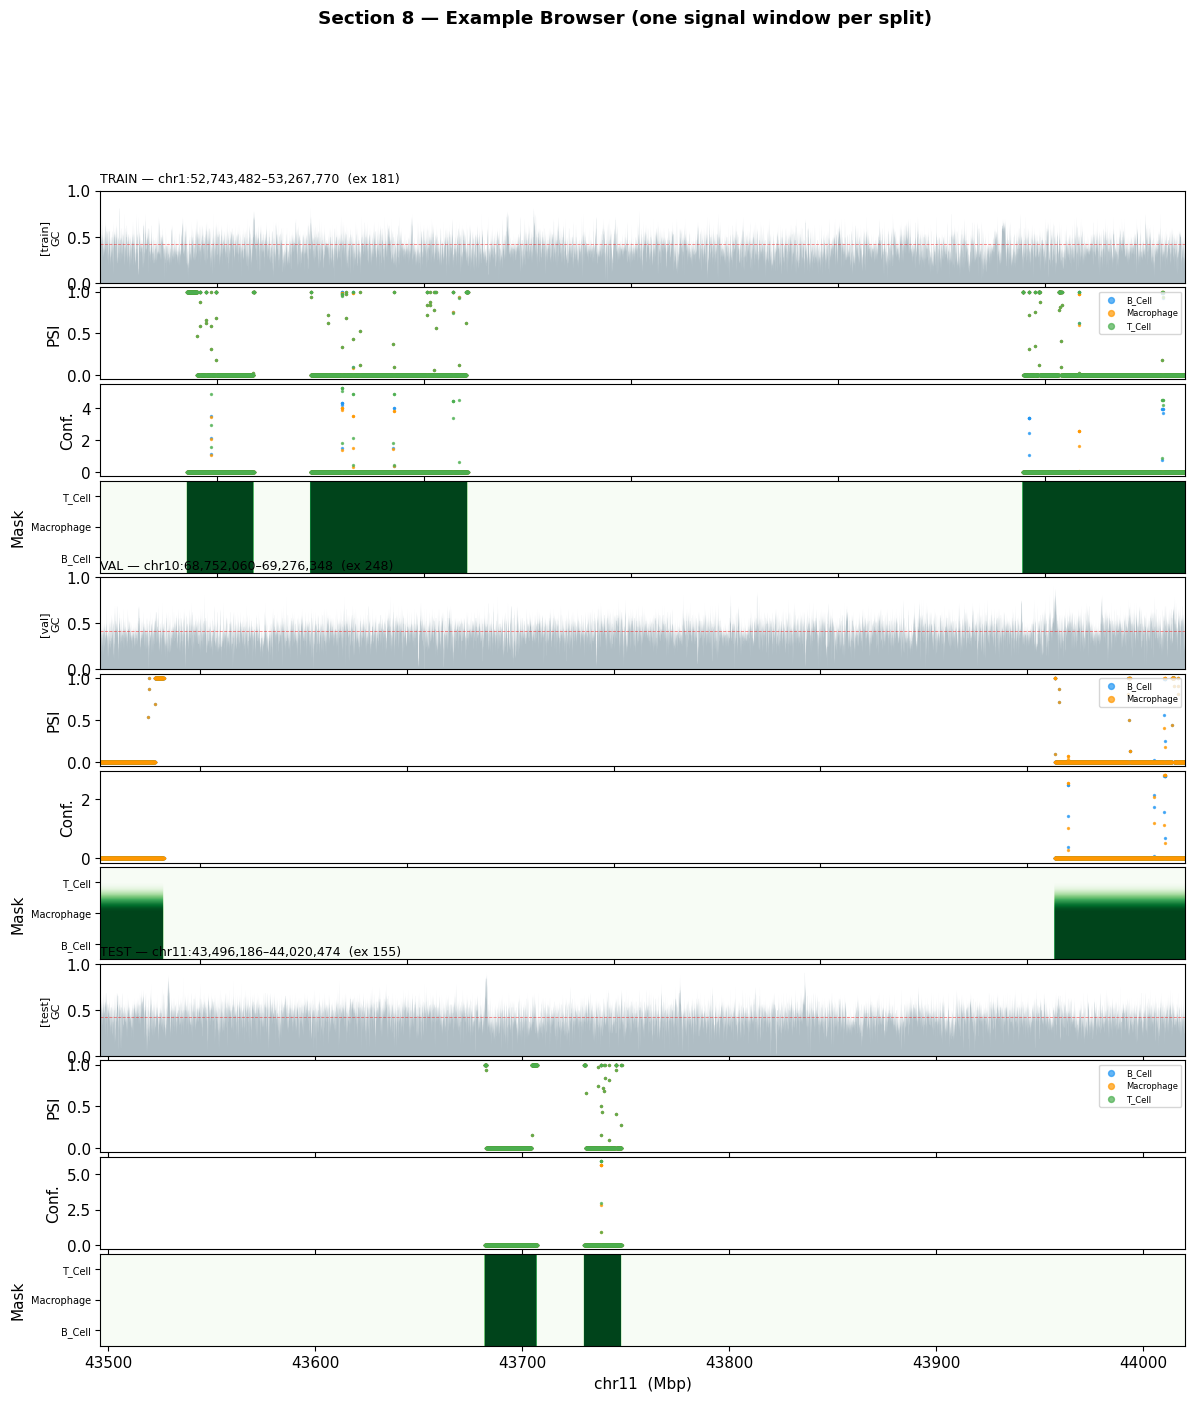

In [11]:
np.random.seed(42)

def plot_example(ax_row, seq, tgt_ex, conf_ex, msk_ex, chrom, w_start, w_end, title):
    """Draw a 4-row strip (GC, PSI, confidence, mask) into ax_row (list of 4 axes)."""
    bp_axis = np.arange(N_BINS) * BIN_BP + w_start
    # sequence GC (downsampled to bins)
    seq_binned = seq.reshape(N_BINS, BIN_BP, 4).sum(axis=1)   # (N_BINS, 4)
    gc = (seq_binned[:, 1] + seq_binned[:, 2]) / BIN_BP

    # 0: GC
    ax = ax_row[0]
    ax.fill_between(bp_axis / 1e3, gc, alpha=0.5, color="#607d8b", linewidth=0)
    ax.set_ylim(0, 1); ax.set_ylabel("GC")
    ax.set_title(title, fontsize=9, loc="left")
    ax.axhline(0.42, color="red", linewidth=0.6, linestyle="--", alpha=0.5)

    # 1: PSI
    ax = ax_row[1]
    for i, ct in enumerate(CELL_TYPES):
        m = msk_ex[:, i] == 1
        if m.any():
            ax.scatter(bp_axis[m] / 1e3, tgt_ex[m, i],
                       s=2, color=cell_color(ct), alpha=0.7, label=ct)
    ax.set_ylim(-0.05, 1.05); ax.set_ylabel("PSI")
    ax.legend(fontsize=6, loc="upper right", markerscale=3)

    # 2: Confidence
    ax = ax_row[2]
    for i, ct in enumerate(CELL_TYPES):
        m = msk_ex[:, i] == 1
        if m.any():
            ax.scatter(bp_axis[m] / 1e3, conf_ex[m, i],
                       s=2, color=cell_color(ct), alpha=0.7)
    ax.set_ylabel("Conf.")

    # 3: Mask heatmap
    ax = ax_row[3]
    ax.imshow(msk_ex.T, aspect="auto", origin="lower", cmap="Greens",
              vmin=0, vmax=1,
              extent=[bp_axis[0] / 1e3, bp_axis[-1] / 1e3, -0.5, N_TASKS - 0.5])
    ax.set_yticks(range(N_TASKS)); ax.set_yticklabels(CELL_TYPES, fontsize=7)
    ax.set_ylabel("Mask")
    ax.set_xlabel(f"{chrom}  (Mbp)")

    for a in ax_row[:-1]:
        a.set_xticklabels([])
        a.set_xlim(bp_axis[0] / 1e3, bp_axis[-1] / 1e3)
    ax_row[3].set_xlim(bp_axis[0] / 1e3, bp_axis[-1] / 1e3)


fig, all_axes = plt.subplots(4 * len(SPLITS), 1, figsize=(14, 5 * len(SPLITS)),
                              gridspec_kw={"hspace": 0.05})
fig.suptitle("Section 8 — Example Browser (one signal window per split)",
             fontweight="bold", y=1.001)

for row_set, s in enumerate(SPLITS):
    # Pick a random signal-containing example from the first shard of this split
    f = all_shards[s][0]
    d = np.load(f, allow_pickle=True, mmap_mode="r")
    signal_idx = np.where(d["has_signal"] == 1.0)[0]
    if len(signal_idx) == 0:
        signal_idx = np.arange(len(d["has_signal"]))
    ex_i = np.random.choice(signal_idx)

    chrom      = str(d["chrom"][ex_i])
    w_start    = int(d["window_start"][ex_i])
    w_end      = int(d["window_end"][ex_i])
    seq_ex     = np.array(d["sequence"][ex_i])    # (WINDOW_BP, 4)
    tgt_ex     = np.array(d["targets"][ex_i])     # (N_BINS, N_TASKS)
    conf_ex    = np.array(d["confidence"][ex_i])  # (N_BINS, N_TASKS)
    msk_ex     = np.array(d["mask"][ex_i])        # (N_BINS, N_TASKS)

    ax_row = all_axes[row_set * 4 : row_set * 4 + 4]
    title = f"{s.upper()} — {chrom}:{w_start:,}–{w_end:,}  (ex {ex_i})"
    plot_example(ax_row, seq_ex, tgt_ex, conf_ex, msk_ex,
                 chrom, w_start, w_end, title)

    # Add split label on left
    ax_row[0].set_ylabel(f"[{s}]\nGC", fontsize=8)

plt.tight_layout()
plt.show()

---
## Section 9 — Summary Report
Aggregate statistics and final PASS / WARNING / FAIL verdict.

In [12]:
print("=" * 60)
print("  SUMMARY REPORT")
print("=" * 60)

# ---- Schema checks ----
n_pass = sum(1 for v in summary.values() if v[0])
n_fail = len(summary) - n_pass
print(f"\n[Schema checks]  {n_pass}/{len(summary)} passed  |  {n_fail} failed")
for name, (passed, failures) in summary.items():
    if not passed:
        print(f"  ❌ {name}: {failures[0]}")

# ---- Dataset counts ----
print("\n[Dataset counts]")
for s in SPLITS:
    m = meta[s]
    total = len(m)
    sig_pct = m["has_signal"].mean() * 100
    n_shards = len(all_shards[s])
    print(f"  {s:6s}: {total:6d} examples  "
          f"{n_shards:3d} shards  "
          f"has_signal={sig_pct:.1f}%")

# ---- PSI statistics (train, masked bins) ----
print("\n[PSI statistics — train, masked bins]")
print(f"{'Cell type':<14} {'Mean PSI':>10} {'Std PSI':>8} {'<0.1':>8} {'0.1-0.9':>9} {'>0.9':>8}")
lbl_tr = labels["train"]
for i, ct in enumerate(CELL_TYPES):
    m = lbl_tr["mask"][:, :, i] == 1
    vals = lbl_tr["targets"][:, :, i][m]
    if len(vals) == 0:
        print(f"  {ct:<12}  no labeled bins")
        continue
    pct_low  = (vals <  0.1).mean() * 100
    pct_mid  = ((vals >= 0.1) & (vals <= 0.9)).mean() * 100
    pct_high = (vals >  0.9).mean() * 100
    print(f"  {ct:<12}  {vals.mean():>9.4f}  {vals.std():>7.4f}  "
          f"{pct_low:>7.1f}%  {pct_mid:>8.1f}%  {pct_high:>7.1f}%")

# ---- Mask coverage ----
print("\n[Mask coverage — train, sampled shards]")
for i, ct in enumerate(CELL_TYPES):
    frac = lbl_tr["mask"][:, :, i].sum(axis=1) / N_BINS
    pct_ex = (frac > 0).mean() * 100
    print(f"  {ct:<14}  median frac_labeled={np.median(frac):.4f}  "
          f"% examples w/ any signal={pct_ex:.1f}%")

# ---- GC content ----
print("\n[Sequence — GC content]")
for s in SPLITS:
    if s in gc_all:
        g = gc_all[s]
        print(f"  {s:6s}: mean={g.mean():.4f}  std={g.std():.4f}")

# ---- Verdict ----
print("\n" + "=" * 60)
issues = []
if n_fail > 0:
    issues.append(f"{n_fail} schema check(s) failed")
for s in SPLITS:
    r = meta[s]["has_signal"].mean()
    if r < 0.3 or r > 0.9:
        issues.append(f"{s} has_signal rate={r:.2f} (unusual)")
for s in SPLITS:
    if gc_all.get(s) is not None:
        gc_mean = gc_all[s].mean()
        if gc_mean < 0.35 or gc_mean > 0.55:
            issues.append(f"{s} GC mean={gc_mean:.3f} (unusual for mm10)")

if not issues:
    print("  ✅  PASS — all checks passed, distributions look nominal.")
elif n_fail == 0:
    print("  ⚠️   WARNING — schema OK but review the following:")
    for iss in issues:
        print(f"    • {iss}")
else:
    print("  ❌  FAIL — schema errors detected:")
    for iss in issues:
        print(f"    • {iss}")
print("=" * 60)

  SUMMARY REPORT

[Schema checks]  17/17 passed  |  0 failed

[Dataset counts]
  train :   8725 examples   44 shards  has_signal=68.2%
  val   :    483 examples    2 shards  has_signal=70.0%
  test  :    453 examples    2 shards  has_signal=77.0%

[PSI statistics — train, masked bins]
Cell type        Mean PSI  Std PSI     <0.1   0.1-0.9     >0.9
  B_Cell           0.0967   0.2884     89.4%       1.9%      8.7%
  Macrophage       0.0798   0.2651     91.3%       1.4%      7.3%
  T_Cell           0.0865   0.2748     90.6%       1.6%      7.9%

[Mask coverage — train, sampled shards]
  B_Cell          median frac_labeled=0.0584  % examples w/ any signal=64.4%
  Macrophage      median frac_labeled=0.0824  % examples w/ any signal=66.7%
  T_Cell          median frac_labeled=0.0620  % examples w/ any signal=65.0%

[Sequence — GC content]
  train : mean=0.4019  std=0.0255
  val   : mean=0.4071  std=0.0322
  test  : mean=0.4230  std=0.0365

  ✅  PASS — all checks passed, distributions look nom